# Data exploration

The behaviour of the 15 fish in the bout table (`data/bouts_clean.csv`, from 01_bout_discretisation.ipynb): the
figures and the numbers of the Data chapter. Distances in mm at the physical 3.60 px/mm.

<a id="contents"></a>
**Contents**

- [Every number quoted in the Data chapter](#every-number-quoted-in-the-data-chapter)
- [The three channels of a bout, per fish (Figure fig:marginals)](#the-three-channels-of-a-bout-per-fish-figure-fig)
- [Quiescence (Figure fig:quiescence)](#quiescence-figure-fig-quiescence)
- [Turning toward the dots, per fish (Figure fig:stimbars)](#turning-toward-the-dots-per-fish-figure-fig-stim)
- [Distance to the dots across the block, by condition (Figure fig:dotprofile)](#distance-to-the-dots-across-the-block-by-conditi)
- [Spatial structure (Figure fig:spatial)](#spatial-structure-figure-fig-spatial)
- [Slow fluctuations over the session (Figure fig:slowdata)](#slow-fluctuations-over-the-session-figure-fig-sl)
- [Individuality (Figure fig:individuality)](#individuality-figure-fig-individuality)
- **[Beyond the Data chapter](#beyond-the-data-chapter)**
  - [Is 10 s the right cut for a pause?](#is-10-s-the-right-cut-for-a-pause)
  - [The whole session of one fish, with the pauses](#the-whole-session-of-one-fish-with-the-pauses)
  - [Where the fish is when still, and when active](#where-the-fish-is-when-still-and-when-active)
  - [Does behaviour change over the session?](#does-behaviour-change-over-the-session)
  - [How far back does a bout remember?](#how-far-back-does-a-bout-remember)
  - [The long timescale: the fish or the schedule?](#the-long-timescale-the-fish-or-the-schedule)

In [1]:
from figures import data_figures, fig_slow_data
c = data_figures.load()

<a id="every-number-quoted-in-the-data-chapter"></a>
## Every number quoted in the Data chapter

[↑ back to contents](#contents)

In [2]:
data_figures.stats(c)

NUMBERS QUOTED IN CHAPTER 3
fish                     : 15
frames per fish          : 313500  (174.17 min)
blocks                   : 190 (50 s pause + 60 s stimulus, 95 pairs)
stimulus conditions      : 16
bouts detected           : 71,937
active bouts             : 69,572  (96.71%)
runs                     : 1,298  (median 11 bouts)
bouts with dots on       : 40,872 (56.8%)
crosses_block            : 1,864 (2.7% of active)

dt_s      median 1.233  IQR 0.900-1.733  95th 3.60  -> 0.81 Hz
dist  px  median 14.87  mm 4.13  95th 8.26 mm
|dtheta|  median 38.6 deg  95th 108.7 deg
bout type : right=0.448, left=0.440, forward=0.112
speed     median 3.30 mm/s

quiescent share  pooled 29.5%  per-fish 5.0-74.0% (fish 5..6)
bouts ending in a gap    : 1.8% (interval > 10 s)
longest gap              : 426.5 s
dot centroid outside dish: 11.4% of stimulus bouts (moving: 1 dot 16.4%, 2 dots 6.3%, 4 dots 8.3%, 6 dots 11.3%, 8 dots 11.0%)
bouts per fish           : 2,903-6,791

P(turn toward) moving : poo

P(turn toward) static : pooled 0.551  per-fish 0.512-0.566  above 0.5 in 15/15
r_norm    median 0.439  per-fish 0.333-0.682

----------------------------------------------------------------
SEC 3.3  BEHAVIOURAL PROPERTIES
----------------------------------------------------------------
  P(turn toward) |dth|>   0 moving : pooled 0.623 [0.615, 0.631]  mean-of-fish 0.623  per-fish 0.558-0.696  above 0.5 in 15/15


  P(turn toward) |dth|>   0 static : pooled 0.550 [0.540, 0.561]  mean-of-fish 0.541  per-fish 0.481-0.565  above 0.5 in 14/15
  P(turn toward) |dth|>  10 moving : pooled 0.633 [0.624, 0.642]  mean-of-fish 0.636  per-fish 0.554-0.724  above 0.5 in 15/15


  P(turn toward) |dth|>  10 static : pooled 0.550 [0.539, 0.561]  mean-of-fish 0.540  per-fish 0.471-0.568  above 0.5 in 14/15
  share of stimulus bouts with |dtheta| <= 10 deg: 0.115

  approach moving  N=1: first 8 s  19.9 mm -> last 15 s  28.3 mm   ( +8.4)
  approach moving  N=2: first 8 s  18.6 mm -> last 15 s  19.2 mm   ( +0.7)
  approach moving  N=4: first 8 s  17.4 mm -> last 15 s  20.6 mm   ( +3.2)
  approach moving  N=6: first 8 s  18.2 mm -> last 15 s  19.9 mm   ( +1.7)
  approach moving  N=8: first 8 s  15.9 mm -> last 15 s  19.8 mm   ( +3.8)
  approach static  N=1: first 8 s  25.0 mm -> last 15 s  35.9 mm   (+10.9)
  approach static  N=4: first 8 s  21.4 mm -> last 15 s  35.4 mm   (+14.0)
  approach static  N=8: first 8 s  21.6 mm -> last 15 s  34.8 mm   (+13.1)

  P(turn toward centre) centre  r/R<0.3: 0.568  per-fish 0.460-0.602  above 0.5 in 13/15
  P(turn toward centre) mid     0.3-0.7: 0.595  per-fish 0.522-0.635  above 0.5 in 15/15
  P(turn toward centre) outer   r/R>

  lag-1 corr displacement  : median +0.284  range +0.192..+0.384  same sign in 15/15
    lags 1-5 displacement : +0.284  +0.187  +0.143  +0.112  +0.099   vs one-step decay +0.284  +0.081  +0.023  +0.007  +0.002
  lag-1 corr interval      : median +0.147  range +0.068..+0.312  same sign in 15/15
    lags 1-5 interval     : +0.147  +0.109  +0.106  +0.083  +0.072   vs one-step decay +0.147  +0.022  +0.003  +0.000  +0.000
  lag-1 corr |dtheta|      : median +0.092  range +0.033..+0.198  same sign in 15/15


    lags 1-5 |dtheta|     : +0.092  +0.034  +0.029  +0.025  +0.032   vs one-step decay +0.092  +0.008  +0.001  +0.000  +0.000
  lag-1 corr signed dtheta : median -0.016  range -0.159..+0.143  same sign in 9/15
    lags 1-5 signed dtheta: -0.016  +0.035  +0.027  +0.014  +0.016   vs one-step decay -0.016  +0.000  -0.000  +0.000  -0.000



  60-bout windows: 862 across 15 fish
  within-window step SD     : per-fish median 1.17-2.48 mm  (2.12x across fish)
  within-window interval SD : per-fish median 0.51-1.50 s  (2.95x across fish)

individuality, per-fish window means (the Fig. 3.8 decomposition):
  interval    : per-fish mean 0.929-2.122 s  between-fish SD 0.272  within-fish SD 0.276  ratio B/W 0.98
  displacement: per-fish mean 3.651-6.101 mm  between-fish SD 0.848  within-fish SD 0.594  ratio B/W 1.43
  |dtheta|    : per-fish mean 34.758-58.704 deg  between-fish SD 7.066  within-fish SD 5.584  ratio B/W 1.27
  radial r/R  : per-fish mean 0.390-0.659   between-fish SD 0.085  within-fish SD 0.109  ratio B/W 0.78
  per-fish RANK on each axis (1 = lowest), to show the axes are not one axis:
            dt  dist  adth  rad
   fish_id                     
   0        15     1     2    7
   1        10     7     8    1
   2         8     6    12    8
   3        14    12    10    2
   4        12     9     5   11
   5     

pre-repair bouts > 50 mm/s : 2  (max 96 mm/s)
post-clean max speed     : 39.4 mm/s


<a id="the-three-channels-of-a-bout-per-fish-figure-fig"></a>
## The three channels of a bout, per fish (Figure fig:marginals)

[↑ back to contents](#contents)

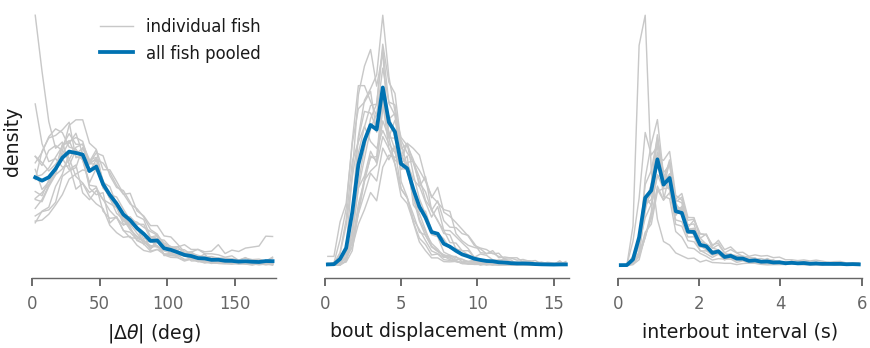

In [3]:
data_figures.fig_marginals(c)

<a id="quiescence-figure-fig-quiescence"></a>
## Quiescence (Figure fig:quiescence)

[↑ back to contents](#contents)

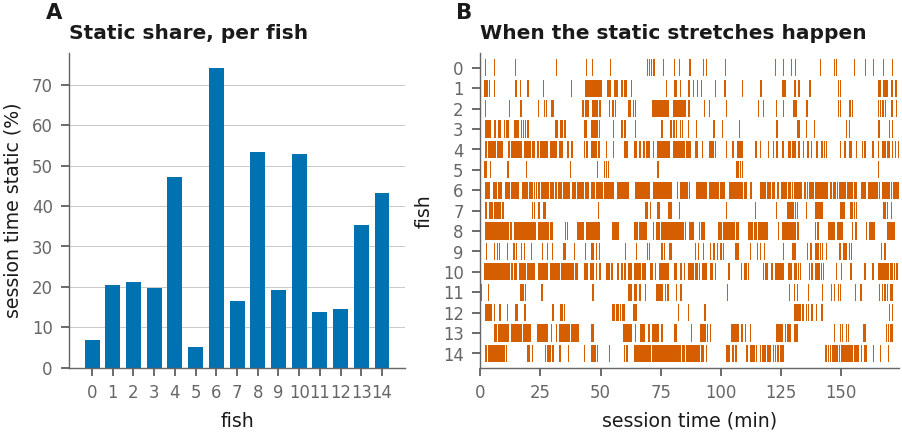

In [4]:
data_figures.fig_quiescence(c)

<a id="turning-toward-the-dots-per-fish-figure-fig-stim"></a>
## Turning toward the dots, per fish (Figure fig:stimbars)

[↑ back to contents](#contents)

  moving: P(heading at the dots) over stimulus blocks 0.611 [0.602, 0.620], blind fish 0.526 [0.517, 0.534]; above the blind level in 14 of 15 fish


  static: P(heading at the dots) over stimulus blocks 0.467 [0.455, 0.479], blind fish 0.525 [0.517, 0.534]; above the blind level in 0 of 15 fish


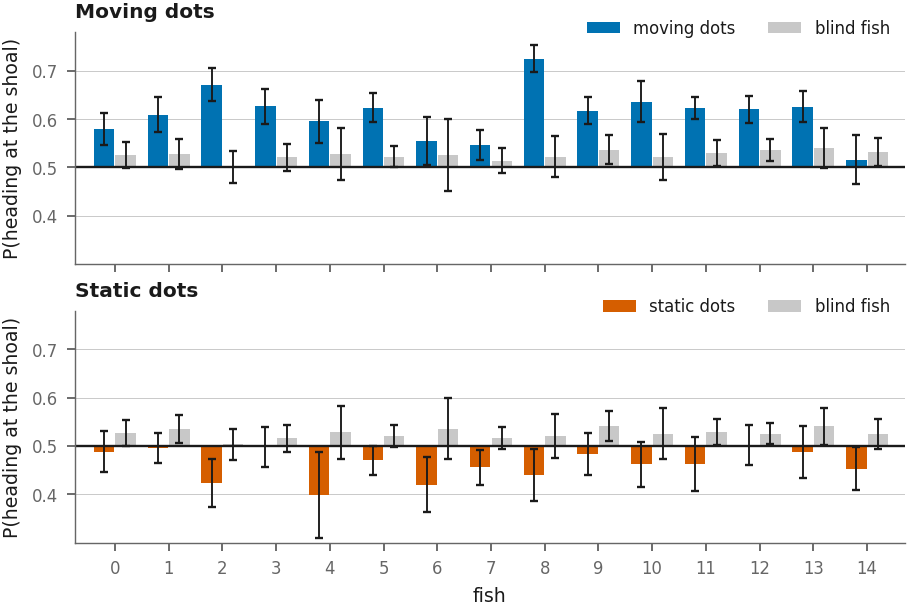

In [5]:
data_figures.fig_stim_bars(c)

<a id="distance-to-the-dots-across-the-block-by-conditi"></a>
## Distance to the dots across the block, by condition (Figure fig:dotprofile)

[↑ back to contents](#contents)

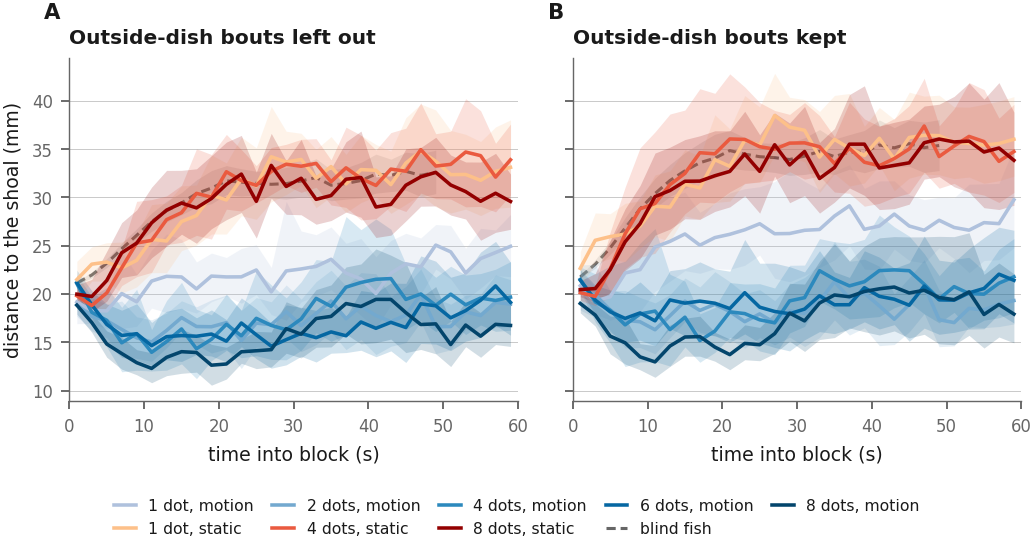

In [6]:
data_figures.fig_dot_profile_pair(c)

<a id="spatial-structure-figure-fig-spatial"></a>
## Spatial structure (Figure fig:spatial)

[↑ back to contents](#contents)

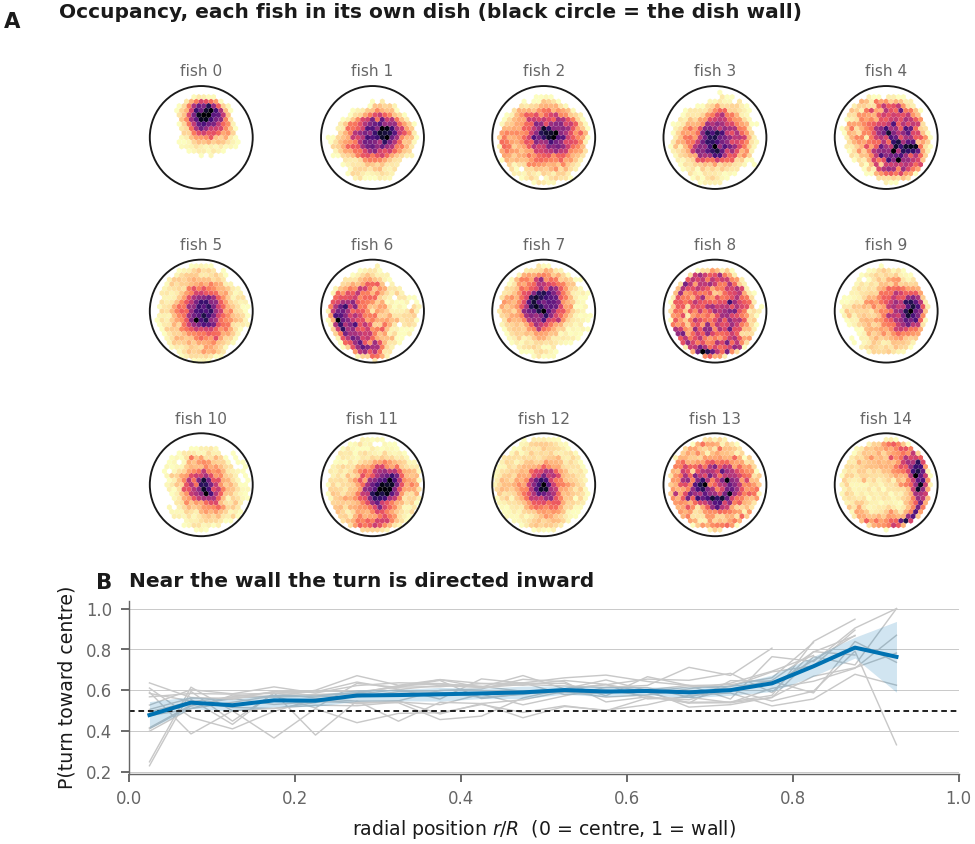

In [7]:
data_figures.fig_spatial(c)

<a id="slow-fluctuations-over-the-session-figure-fig-sl"></a>
## Slow fluctuations over the session (Figure fig:slowdata)

[↑ back to contents](#contents)

example fish 5: 97 windows
dt    real lag1: +0.363±0.159 (n=12)  lag2: +0.181±0.133 (n=12)  lag3: +0.104±0.172 (n=11)  lag4: +0.115±0.165 (n=10)  lag5: +0.111±0.090 (n=8)  lag6: +0.152±0.197 (n=6)
      null lag1: -0.016  lag2: -0.019  lag3: -0.019  lag4: -0.021  lag5: -0.019  lag6: -0.010
dist  real lag1: +0.242±0.165 (n=12)  lag2: +0.170±0.173 (n=12)  lag3: +0.159±0.238 (n=11)  lag4: +0.138±0.109 (n=10)  lag5: +0.127±0.172 (n=8)  lag6: -0.013±0.242 (n=6)
      null lag1: -0.022  lag2: -0.023  lag3: -0.018  lag4: -0.022  lag5: -0.022  lag6: -0.012
turn  real lag1: +0.182±0.091 (n=12)  lag2: -0.055±0.173 (n=12)  lag3: -0.009±0.110 (n=11)  lag4: +0.080±0.139 (n=10)  lag5: +0.093±0.150 (n=8)  lag6: +0.105±0.076 (n=6)
      null lag1: -0.019  lag2: -0.021  lag3: -0.012  lag4: -0.016  lag5: -0.023  lag6: -0.020
rad   real lag1: +0.370±0.133 (n=12)  lag2: +0.299±0.090 (n=12)  lag3: +0.193±0.149 (n=11)  lag4: +0.177±0.240 (n=10)  lag5: +0.113±0.266 (n=8)  lag6: +0.015±0.200 (n=6)
      null 

  wrote figures/out/fig_slow_data_full.pdf


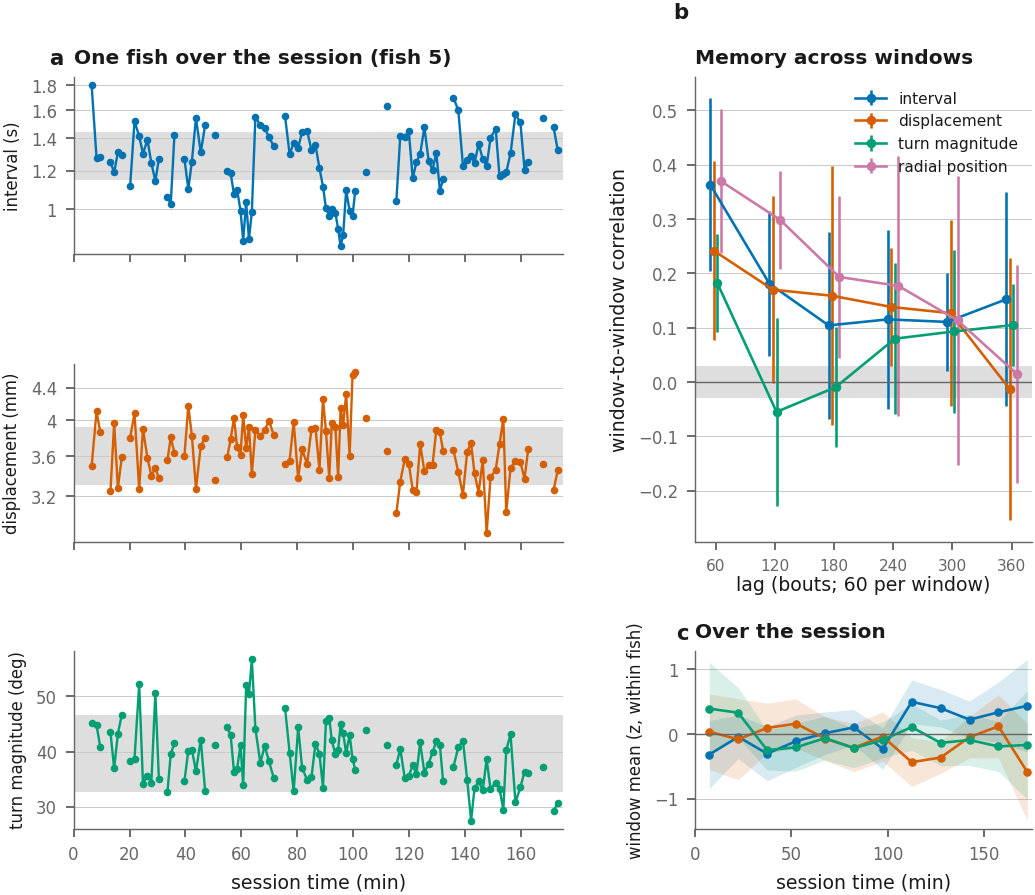

shuffle level of (b), range over channels and lags: -0.023 -0.008


  wrote figures/out/fig_slow_data.pdf


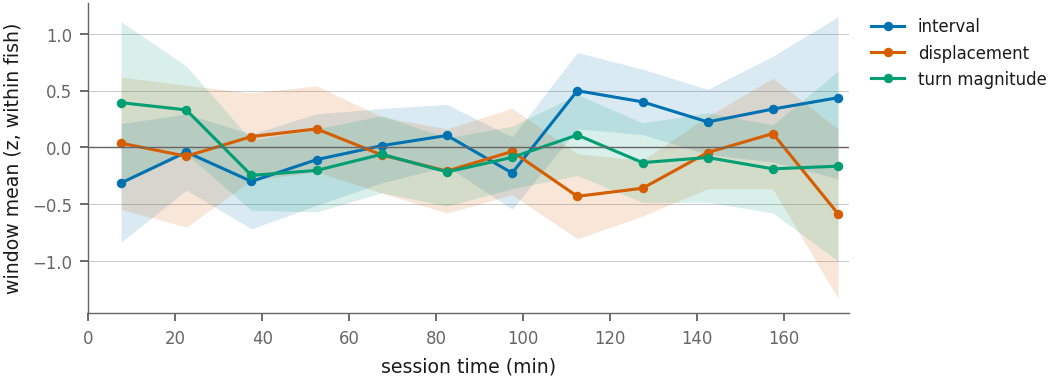

In [8]:
fig_slow_data.main()

<a id="individuality-figure-fig-individuality"></a>
## Individuality (Figure fig:individuality)

[↑ back to contents](#contents)

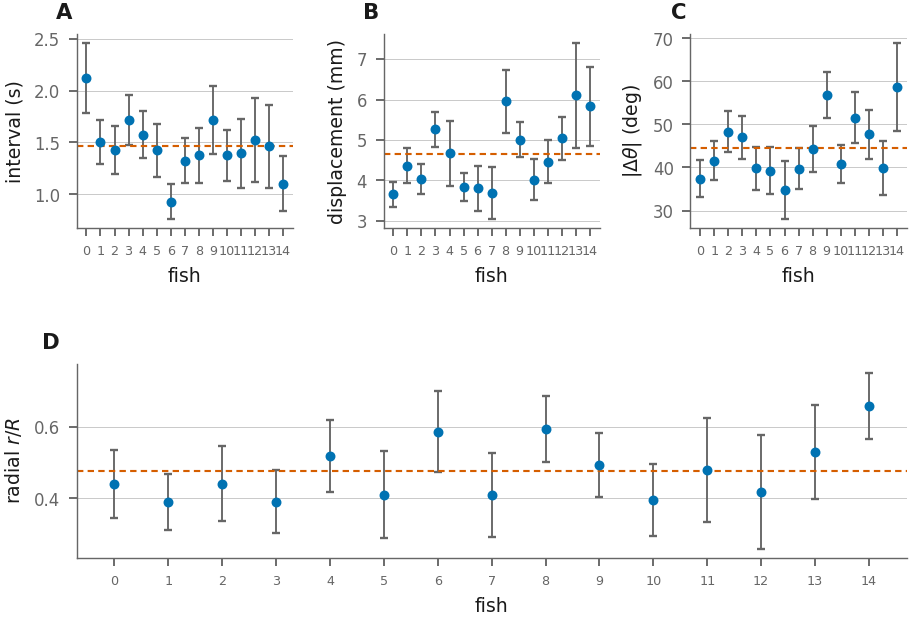

In [9]:
data_figures.fig_individuality(c)

<a id="beyond-the-data-chapter"></a>
# Beyond the Data chapter

The sections below go further than the thesis figures, on the real fish only (`figures/data_explore.py`, the helpers
of the exploration notebook the Data chapter was written from). They read the segmenter's bout table
(`data/bouts_GsizeMotionSingle.csv`), the 30 fps tables (`data/frames/`, sections 9 and 10) and the dish geometry.

[↑ back to contents](#contents)

In [10]:
from figures import data_explore as DE
DE.style()
df = DE.load()
print(f"{len(df):,} bouts, {df.fish_id.nunique()} fish")

71,933 bouts, 15 fish


<a id="is-10-s-the-right-cut-for-a-pause"></a>
## Is 10 s the right cut for a pause?

A bout followed by more than 10 s without one ends a *run*: the 10 s defines which bouts are active and the runs every
model is trained on. Two separate questions:

- **Is there a trough?** If the interval distribution were bimodal (ordinary bouts in one mode, quiescence in another)
  a cut in the dip would be principled. If it is one smooth heavy tail, no cut is, and 10 s is a convention.
- **Does anything move?** If what the models inherit is flat across a wide band of thresholds, the choice is harmless.

[↑ back to contents](#contents)

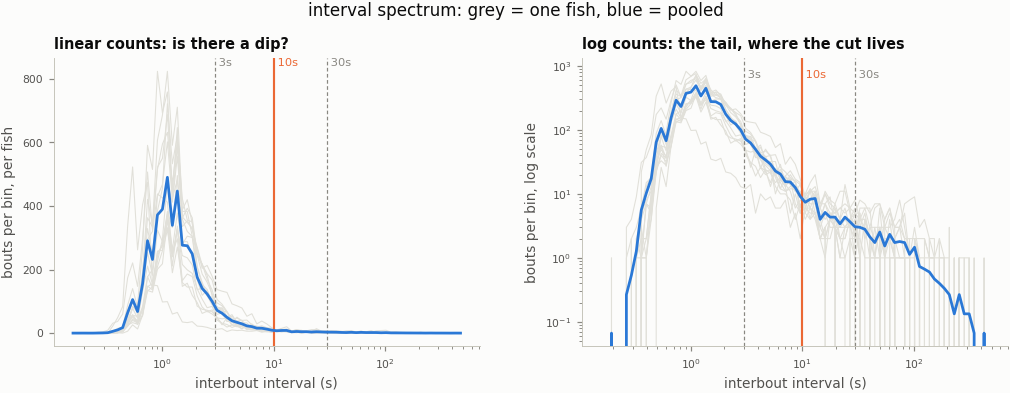

local minima in the smoothed log-interval density above 1 s:
  none: the tail is monotone, so no threshold is picked out by the data


In [11]:
DE.plot_dt_spectrum(df)

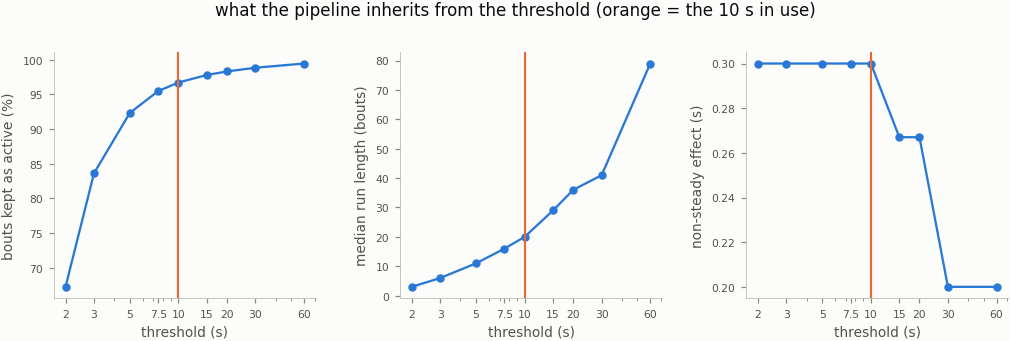

,gaps,pct_session,active,pct_kept,runs_all,runs_act,med_run,dt_med,dt_p99,transient_s
thr_s,,,,,,,,,,
2.0,14096,57.5,48378,67.25,14107,6873,3,1.100,1.97,0.300
3.0,6687,46.0,60149,83.62,6699,4173,6,1.167,2.87,0.300
5.0,3058,37.2,66412,92.32,3072,2137,11,1.200,4.30,0.300
7.5,1787,32.3,68679,95.48,1801,1317,16,1.200,5.70,0.300
10.0,1285,29.5,69567,96.71,1299,979,20,1.233,6.67,0.300
15.0,853,26.2,70353,97.80,867,669,29,1.233,8.07,0.267
20.0,657,24.0,70716,98.31,671,529,36,1.233,9.07,0.267
30.0,441,20.6,71100,98.84,455,380,41,1.233,10.77,0.200
60.0,204,14.2,71535,99.45,218,201,79,1.233,13.23,0.200


In [12]:
DE.threshold_sweep(df)

**Reading it.** There is no dip above 1 s: the tail is monotone, so the data pick out no threshold and 10 s is a
convention, set well clear of ordinary intervals (about 8x the 1.23 s median and above the 99th percentile of 6.7 s).
The share of bouts kept, the median run length and the non-steady effect the run clock carries (the median interval
over a run's first 5 bouts minus the steady value) all vary smoothly with the threshold and nothing happens near 10 s:
the choice is harmless, which is a stronger statement than calling it optimal.

<a id="the-whole-session-of-one-fish-with-the-pauses"></a>
## The whole session of one fish, with the pauses

The 174 minutes of one fish, wrapped over rows: the raw 30 fps speed, the detected bouts and, shaded, the stretches of
more than 10 s without a bout. Change `FISH_ID` (fish 5 is the most active, 6 the least).

[↑ back to contents](#contents)

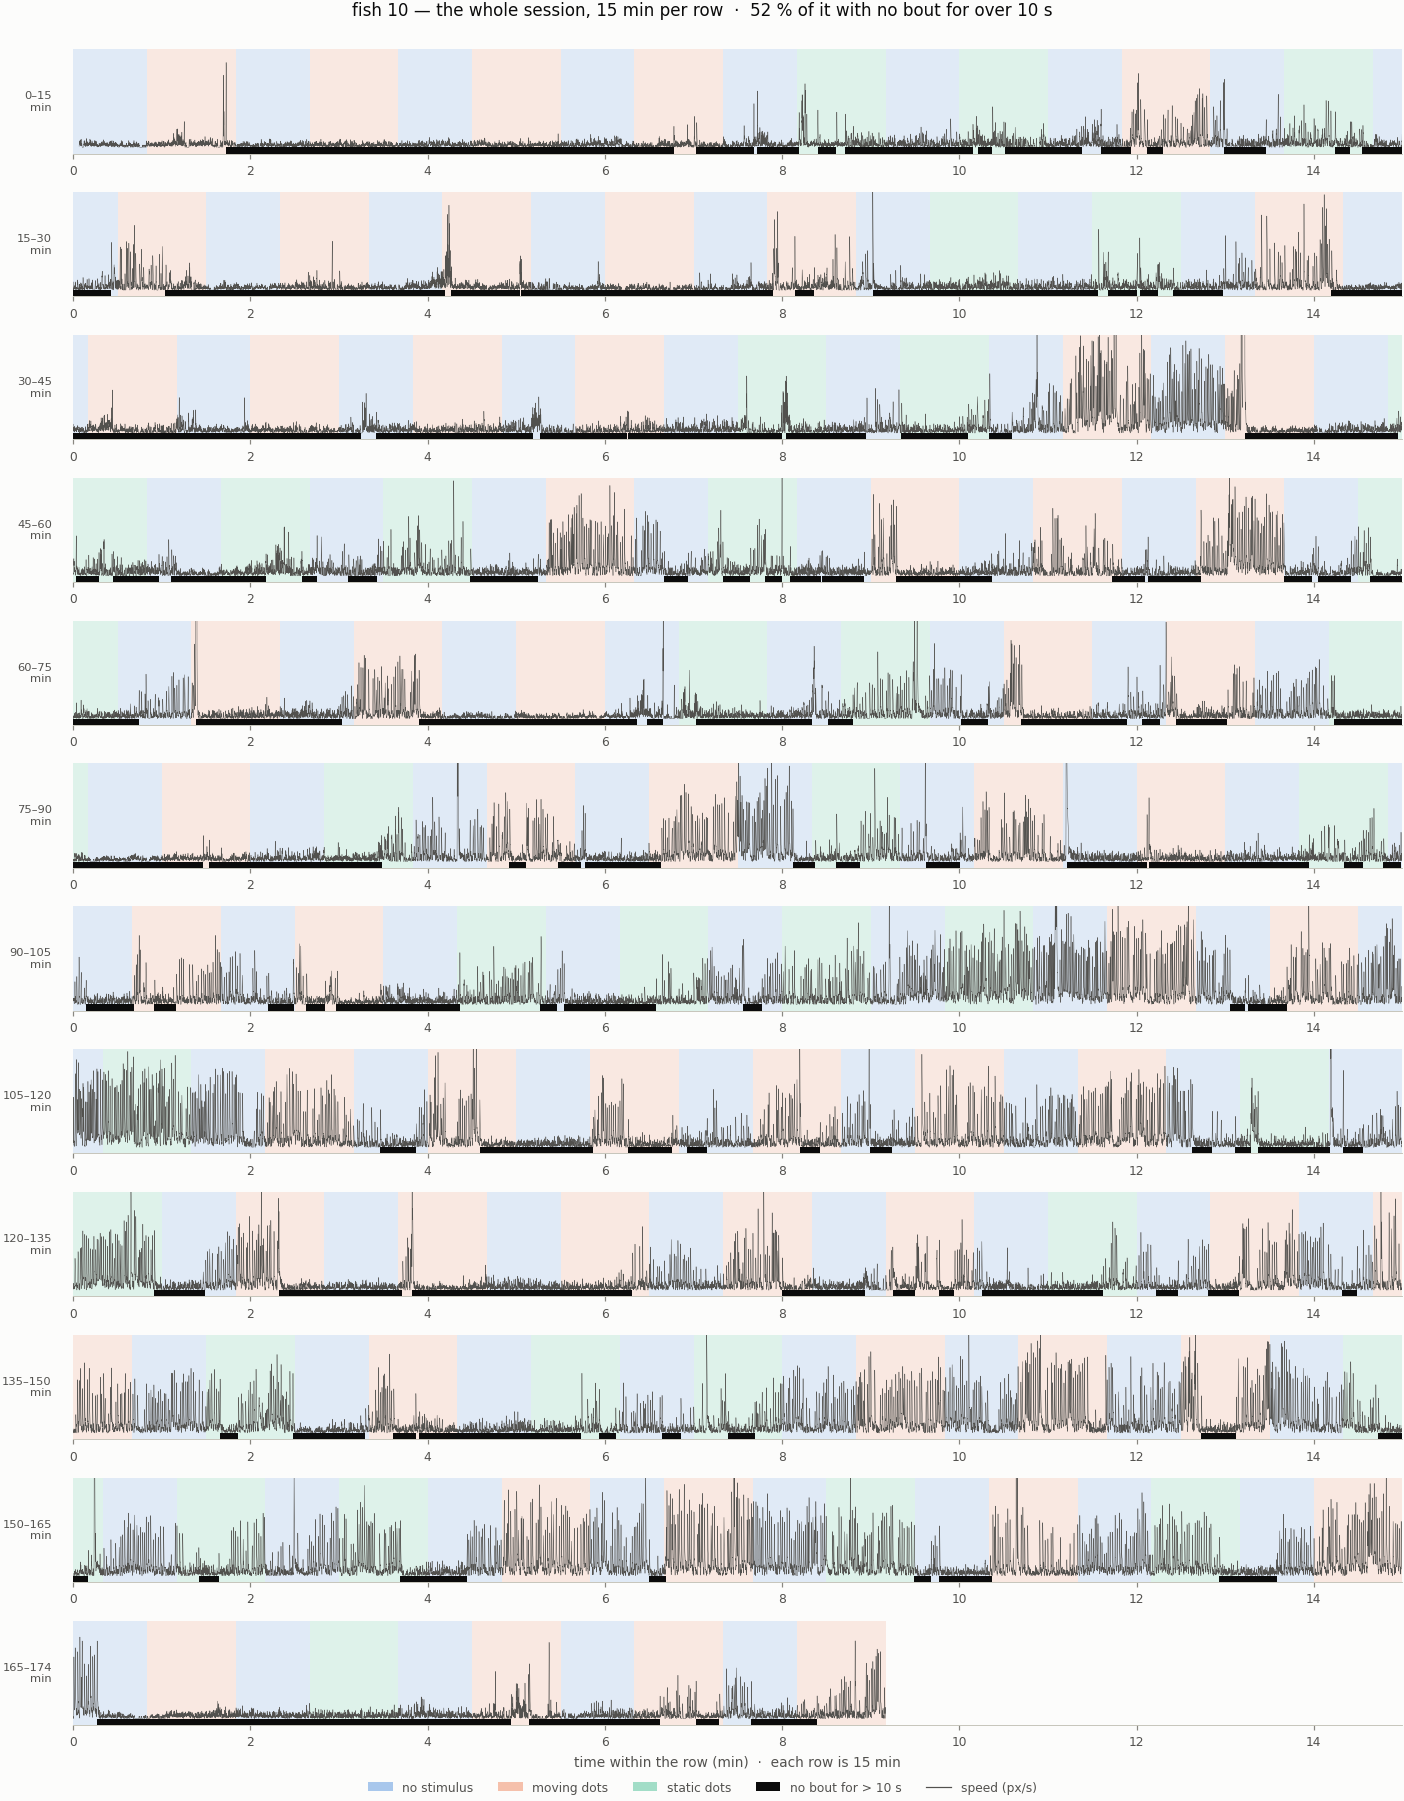

In [13]:
FISH_ID = 10
DE.show(DE.plot_session(df, FISH_ID, row_min=15, thr=10))

<a id="where-the-fish-is-when-still-and-when-active"></a>
## Where the fish is when still, and when active

Occupancy over the frames inside a no-bout stretch of more than 10 s (still) and over every other frame between the
first and the last bout (active), one panel per fish, against the physical 100 mm dish wall (red). A still frame is a
stationary fish, so the first map is dwell time at a few resting spots; the second is where the fish swims. Each panel
is normalised on its own: compare shapes, not intensities. Reads the 15 frame tables the first time (about a minute).

[↑ back to contents](#contents)

dead: 29.3 % of tracked frames on average, mean p99/R = 0.76


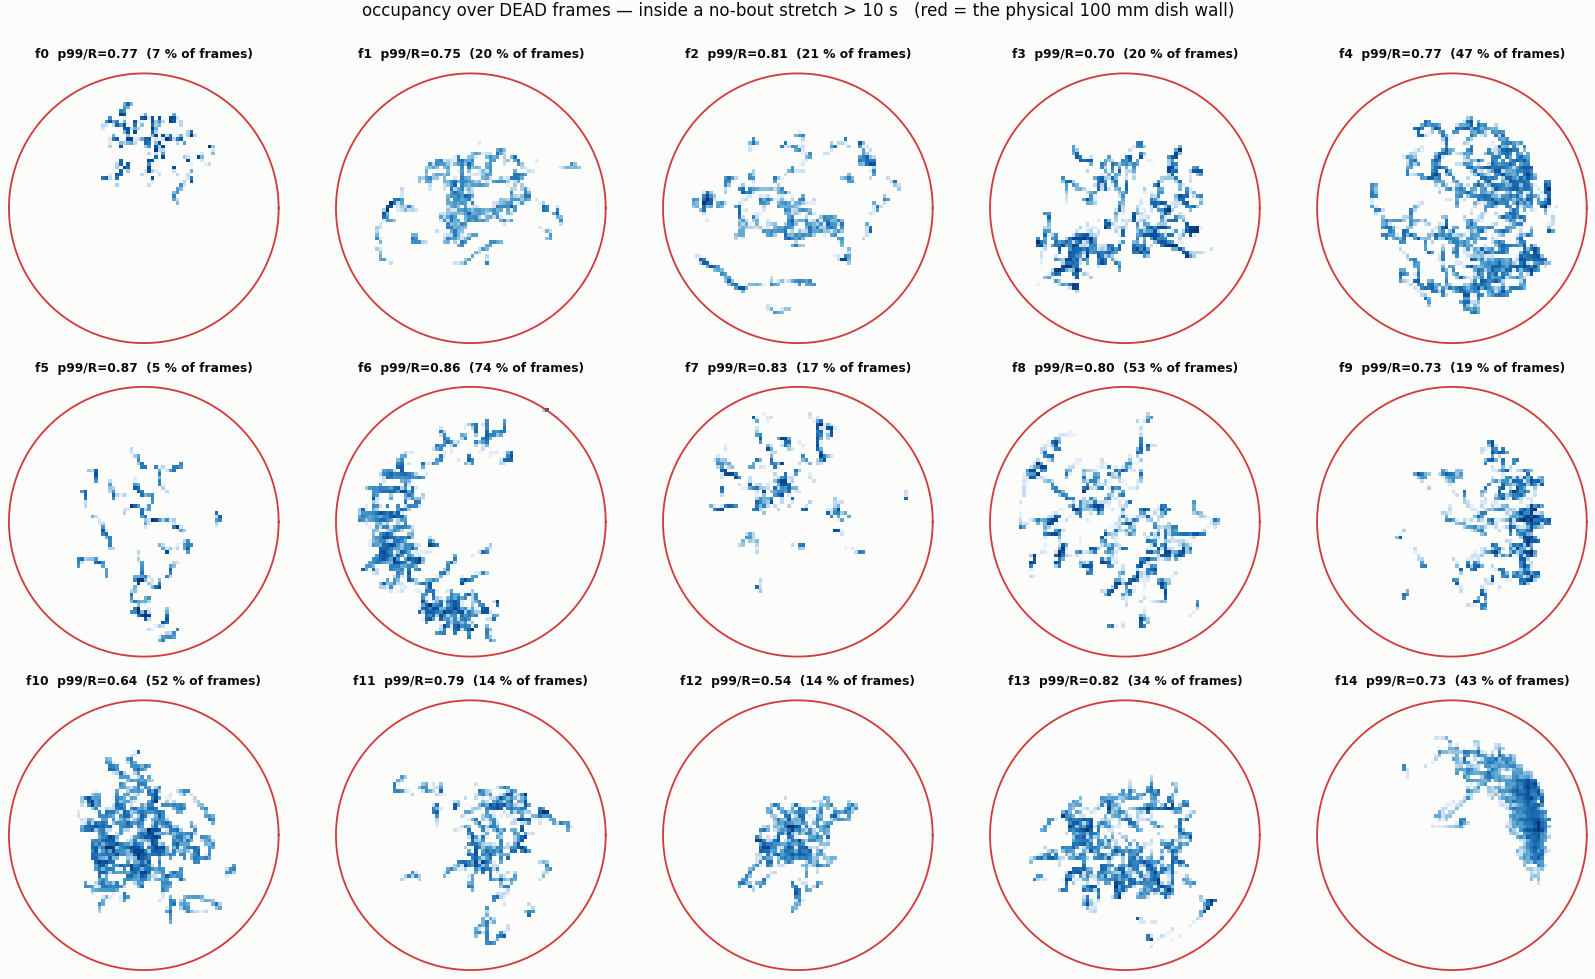

In [14]:
DE.show(DE.plot_occupancy(df, which="dead", thr=10))

active: 70.1 % of tracked frames on average, mean p99/R = 0.83


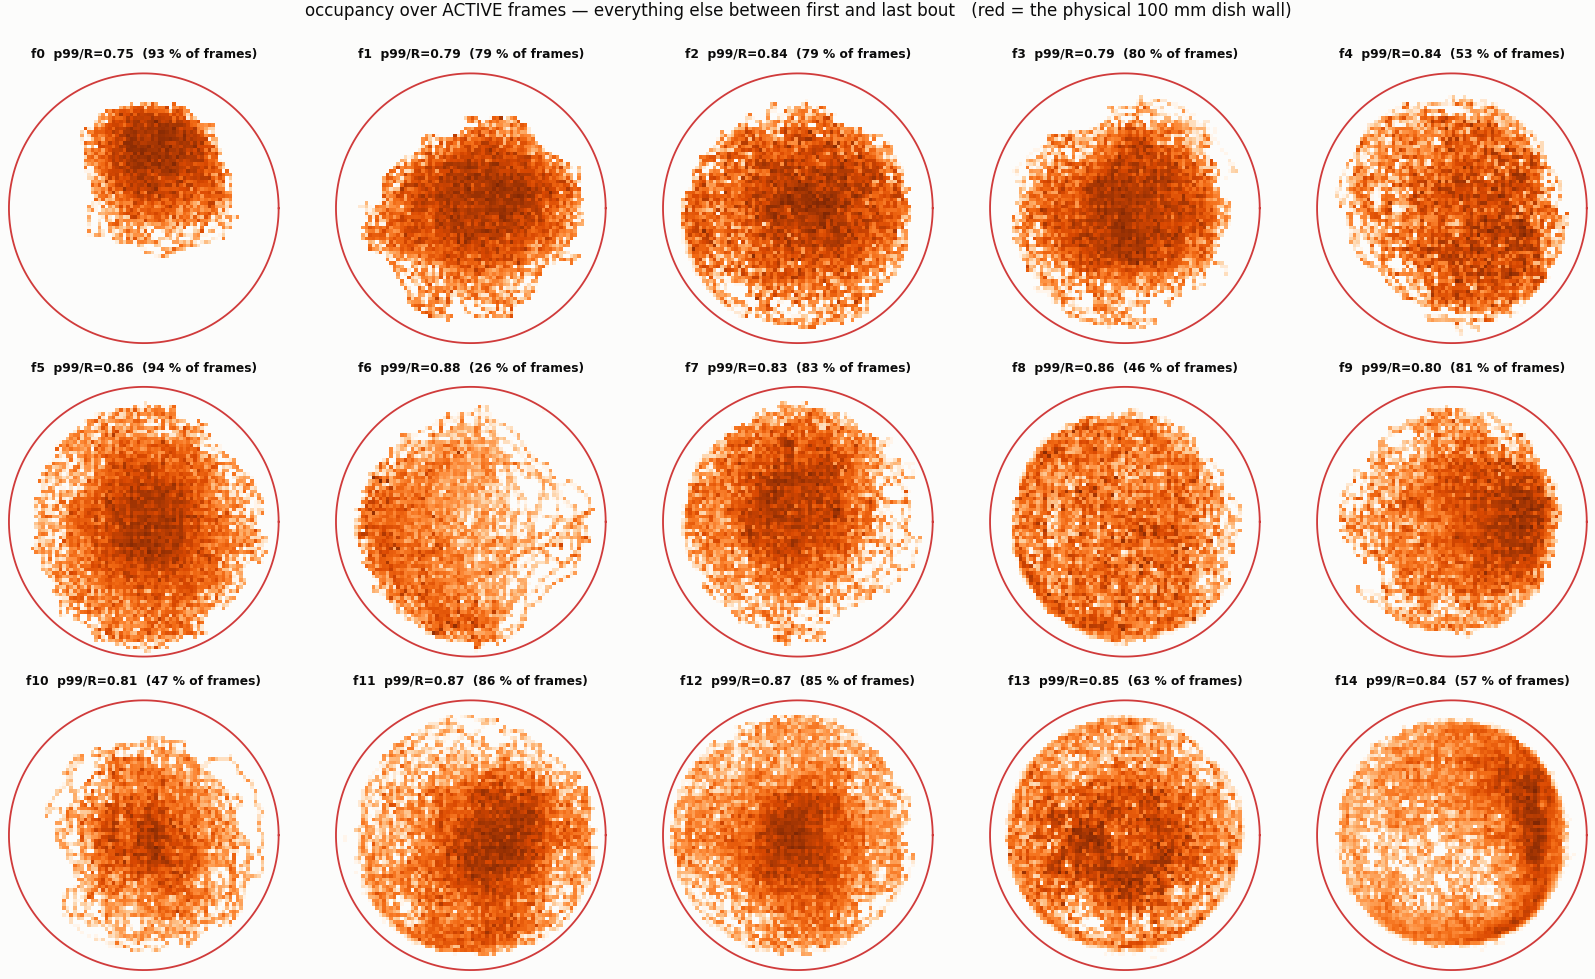

In [15]:
DE.show(DE.plot_occupancy(df, which="active", thr=10))

<a id="does-behaviour-change-over-the-session"></a>
## Does behaviour change over the session?

Whether the fish do something different at the end than at the start, **per fish**, so a session effect cannot be
confused with individuality. A *trend* is monotone change (habituation, fatigue); a *slow fluctuation* is behaviour
correlated over minutes with no direction. Every fish is centred on its own session mean, each fish's Spearman rho is
computed on its own series, and what decides is the sign test across the 15 fish. The kinematic metrics use active
rows only: on a row that spans a pause, the distance and the turn describe the pause, and since quiescence falls over
the session, leaving them in would manufacture a trend. The stimulus schedule is randomised in time, so a trend cannot
be the protocol's order.

The median |turn| per fish and condition in 15 min bins (dashed: the fish's own median; bins with fewer than 20 bouts of
a condition are left empty). Swap `metric=` for `"median Δt (s)"`, `"median dist (px)"` or `"mean r/R"`.

[↑ back to contents](#contents)

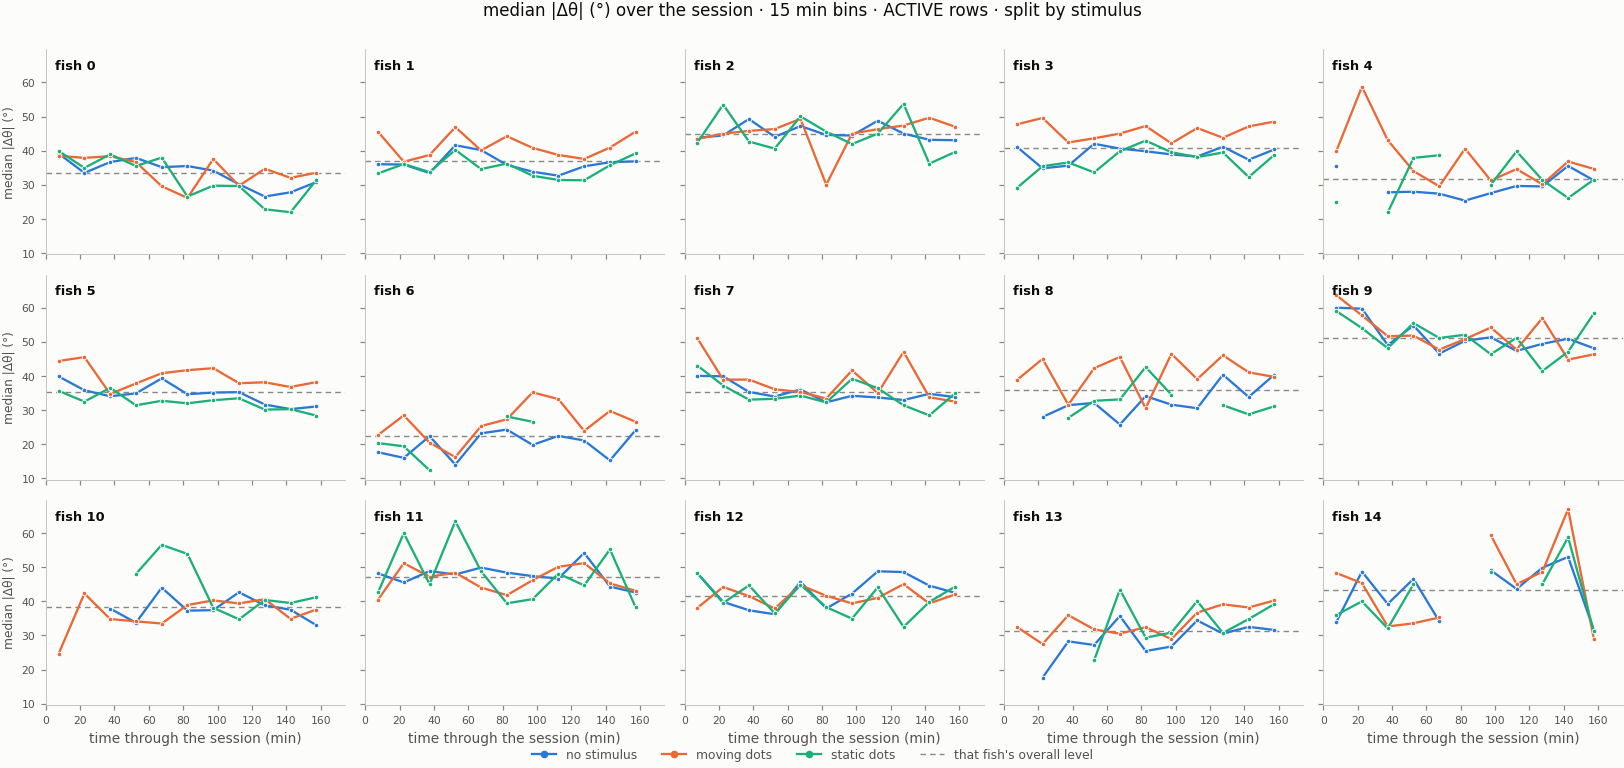

In [16]:
DE.show(DE.plot_metric_over_time(df, metric="median |Δθ| (°)", bin_min=15, kinematics="active"))

The follow index (P(turn toward the dots) - 0.5), the one metric that references the dots; the solid line is chance.
Moving dots stay above static ones in essentially every fish, all session long.

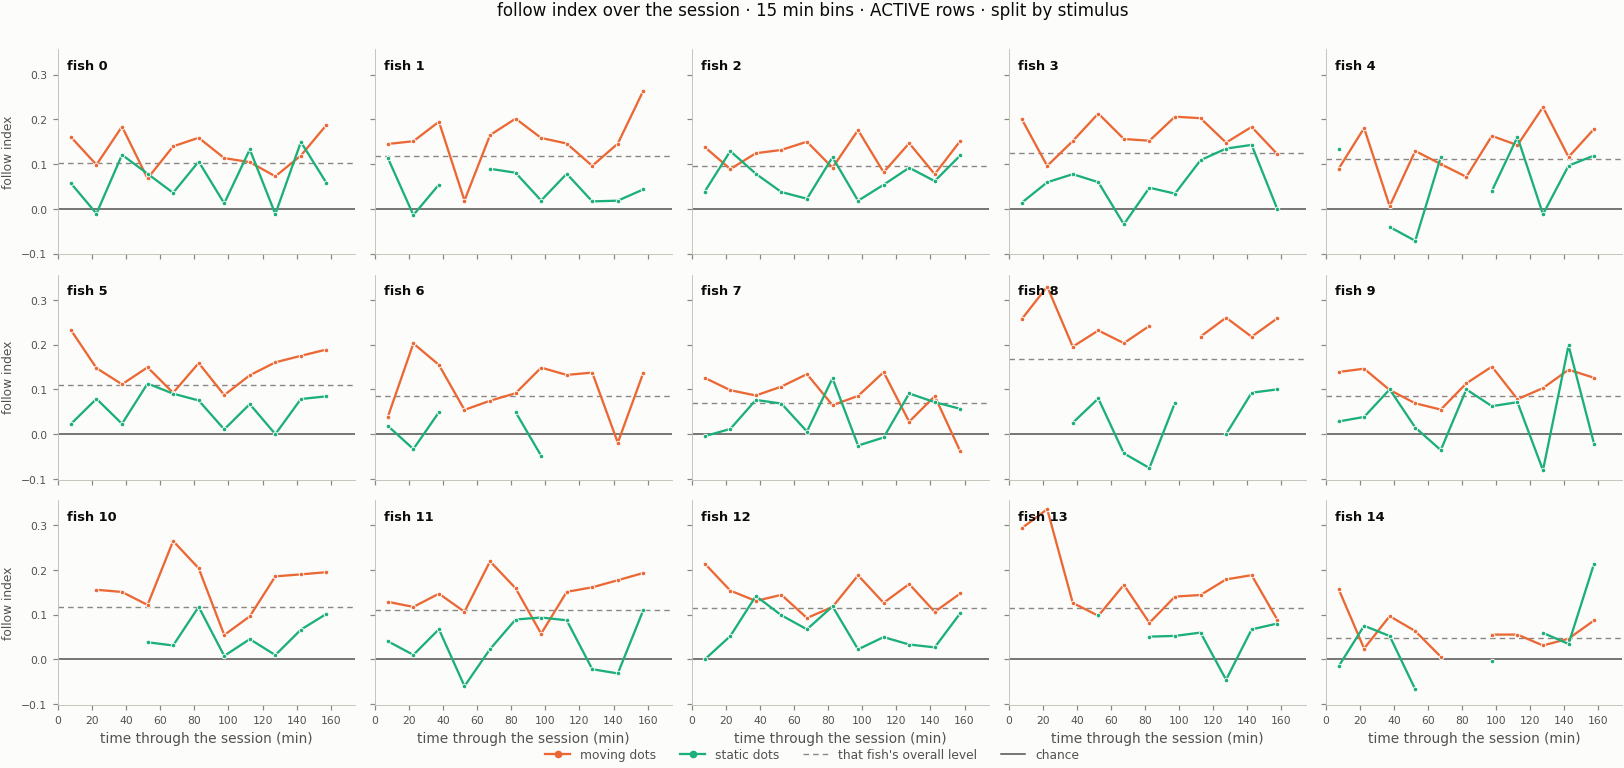

In [17]:
DE.show(DE.plot_metric_over_time(df, metric="follow index", bin_min=15, kinematics="active"))

The population view: every fish centred on its own mean, the mean across fish and its 95 % interval.

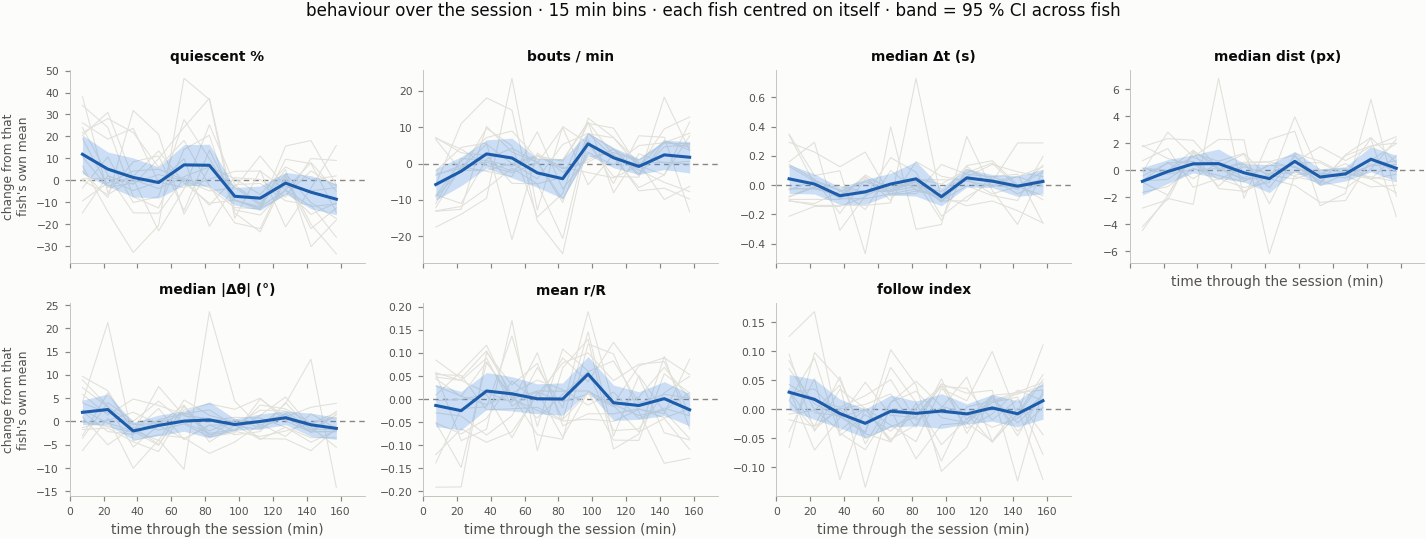

In [18]:
DE.show(DE.plot_time_trends(df, bin_min=15, kinematics="active"))

In [19]:
DE.trend_table(df, bin_min=15)

,mean_rho,same_sign,first_bin,last_bin,sign_test_p
metric,,,,,
quiescent %,-0.289,11/15,41.09,20.59,0.1185
bouts / min,0.204,10/15,21.95,29.45,0.3018
median Δt (s),0.229,11/15,1.29,1.28,0.1185
median dist (px),0.037,8/15,14.25,15.21,1.0000
median |Δθ| (°),-0.135,11/15,40.28,36.84,0.1185
mean r/R,-0.082,8/15,0.43,0.43,1.0000
follow index,0.014,9/15,0.17,0.15,0.6072


Spearman tests for a monotone drift, the wrong instrument if the change is confined to the opening, which is what the
figure suggests (quiescence higher and bout rate lower for about the first half hour). The first 30 min against the
rest, paired within each fish:

In [20]:
DE.settling_table(df, early_min=30, bin_min=15)

,early,rest,diff,same_sign,wilcoxon_p
metric,,,,,
quiescent %,37.70,27.36,10.34,10/15,0.0554
bouts / min,23.78,28.59,-4.81,10/15,0.0637
median Δt (s),1.28,1.24,0.03,8/15,0.6378
median dist (px),14.61,15.18,-0.57,9/15,0.2524
median |Δθ| (°),40.59,37.82,2.77,9/15,0.1205
mean r/R,0.43,0.45,-0.02,8/15,0.5245
follow index,0.16,0.13,0.03,10/15,0.0479


### "No trend" is not "no change"

How much one fish wanders across its own 15 min bins against how much the fish differ from each other: a ratio near 1
means a single fish varies over three hours as much as the fish differ from one another, which is what bout rate and
the follow index do. So individuality estimated from a short window is partly temporal noise, and what to model is a
slow non-directional fluctuation, not a session trend. The settling is not uniform either: a minority of fish carries
it (mean +10 points of quiescence, median much less).

In [21]:
DE.time_variation_table(df, bin_min=15)

,within_fish_sd,between_fish_sd,ratio
metric,,,
follow index,0.049,0.042,1.17
bouts / min,7.564,7.251,1.04
mean r/R,0.069,0.078,0.87
quiescent %,14.112,20.274,0.70
median dist (px),1.427,2.424,0.59
median Δt (s),0.131,0.226,0.58
median |Δθ| (°),4.034,7.160,0.56


### A slow state, or estimation noise?

At 5 min bins: the autocorrelation of each fish's series (sampling noise is white, so a slow state gives acf1 > 0
decaying with lag) and a split-half reliability (each bin's bouts split at random in two, correlated over all fish and
bins; Spearman-Brown gives the share of the variance that is signal). The kinematic channels have a real slow state
(acf1 about 0.18-0.27, gone by lag 3: a timescale of 5-10 minutes; their bin-to-bin variation is mostly signal). The
follow index is the exception: no reproducible within-bin signal, so its within-fish spread is the binomial error on a
few dozen turns, and the stimulus response is stable within a fish.

In [22]:
DE.temporal_structure_table(df, bin_min=5)

,rows,acf1,acf2,acf3,split_half_r,signal_share
metric,,,,,,
quiescent %,all,0.080,0.081,0.041,NaN,NaN
bouts / min,all,0.253,-0.007,-0.017,NaN,NaN
median Δt (s),active,0.185,0.016,-0.039,0.698,0.822
median dist (px),active,0.182,0.158,0.019,0.858,0.924
median |Δθ| (°),active,0.259,0.127,0.084,0.656,0.792
mean r/R,active,0.266,0.066,0.052,0.956,0.978
follow index,active + moving,-0.049,-0.120,-0.004,0.127,0.225


### Does the slow state depend on what is on screen?

The same split by condition, still at 5 min (at 15 min the autocorrelation is gone even pooled, so the bins cannot be
made longer to buy sample size; read `split_half_r` before the acf). Quiescence and bout rate are absent by design:
they are rates over wall-clock time and the exposure to each condition varies from bin to bin. Then the contrast that
matters, paired within fish; `disatt_diff` first divides each condition's acf by its own reliability, since a noisier
estimate is pulled toward 0.

In [23]:
DE.temporal_structure_by_cond(df, bin_min=5)

bouts_per_bin   acf1   acf2  split_half_r
metric           condition                                             
median |Δθ| (°)  no stimulus             64  0.144  0.059         0.644
                 moving dots             51  0.070 -0.011         0.489
                 static dots             31  0.118 -0.006         0.570
median Δt (s)    no stimulus             64  0.275  0.072         0.822
                 moving dots             51  0.048  0.071         0.711
                 static dots             31  0.132 -0.013         0.736
median dist (px) no stimulus             64  0.200 -0.006         0.863
                 moving dots             51  0.129  0.050         0.794
                 static dots             31  0.149 -0.095         0.832
mean r/R         no stimulus             64  0.318 -0.002         0.936
                 moving dots             51  0.114  0.038         0.940
                 static dots             31  0.251  0.049         0.937
follow index     moving dots             51 -0.049 -0.120         0.147
                 static dots             31  0.019 -0.188        -0.201

In [24]:
DE.acf_condition_contrast(df, bin_min=5, a_cond="none", b_cond="moving")

,no stimulus,moving dots,diff,same_sign,wilcoxon_p,disatt_diff
metric,,,,,,
median |Δθ| (°),0.144,0.070,0.074,8/15,0.3894,0.080
median Δt (s),0.275,0.048,0.228,13/15,0.0034,0.268
median dist (px),0.200,0.129,0.070,10/15,0.3591,0.068
mean r/R,0.318,0.114,0.204,12/15,0.0302,0.218


The slow state is weaker under moving dots for the interval and the radial position, in about 12 of 15 fish, with
nearly equal reliabilities, so attenuation does not explain it: with the dots moving those channels are driven from
outside, and during the pauses the fish's own state shows. Several metrics and no multiplicity correction, so this is
suggestive rather than established.

**The control.** The stimulus parameters change from block to block, and a fish's kinematics partly track which
stimulus is on, which would dilute the acf of the moving condition without suppressing anything. Residualising every
bout on its stimulus identity (fish x group size x side) before binning leaves the acf low: the suppression is the
fish, not the schedule.

In [25]:
DE.acf_stimulus_identity_control(df, bin_min=5, a_cond="none", b_cond="moving")

,no stimulus,moving dots raw,moving dots residualised,same_sign,wilcoxon_p
metric,,,,,
mean r/R,0.318,0.114,0.133,12/15,0.0302
median Δt (s),0.275,0.048,0.063,11/15,0.0103
median |Δθ| (°),0.144,0.070,0.057,8/15,0.4212
median dist (px),0.200,0.129,0.108,11/15,0.3591


**Suppressing the drift is not suppressing individuality.** The acf asks whether one fish's deviation persists over
5 min; the between-fish spread asks how far the fish are from each other. The stimulus cuts the first by about 60 % and
the second by 0-18 %: a moving stimulus suppresses each fish's own slow drift while leaving the fish about as different
from one another as they were.

In [26]:
DE.between_fish_sd_by_cond(df)

,no stimulus,moving dots,static dots,ratio_moving_none
metric,,,,
mean r/R,0.084,0.074,0.085,0.87
median Δt (s),0.229,0.236,0.223,1.03
median |Δθ| (°),7.945,6.500,7.226,0.82
median dist (px),2.745,2.535,2.868,0.92


### The 15 fish behind those averages

The same computation, one point per fish (one cell is one fish's ~34 five-minute bins, so a single acf1 has an error of
about ±0.2-0.3: read the column, how many fish land on the same side). A hollow marker: that fish's split-half
reliability is under 0.3 there. The suppression is general for r/R and the interval and not established for |turn|; the
follow index scatters around zero, mostly hollow: a fish's stimulus response does not drift.

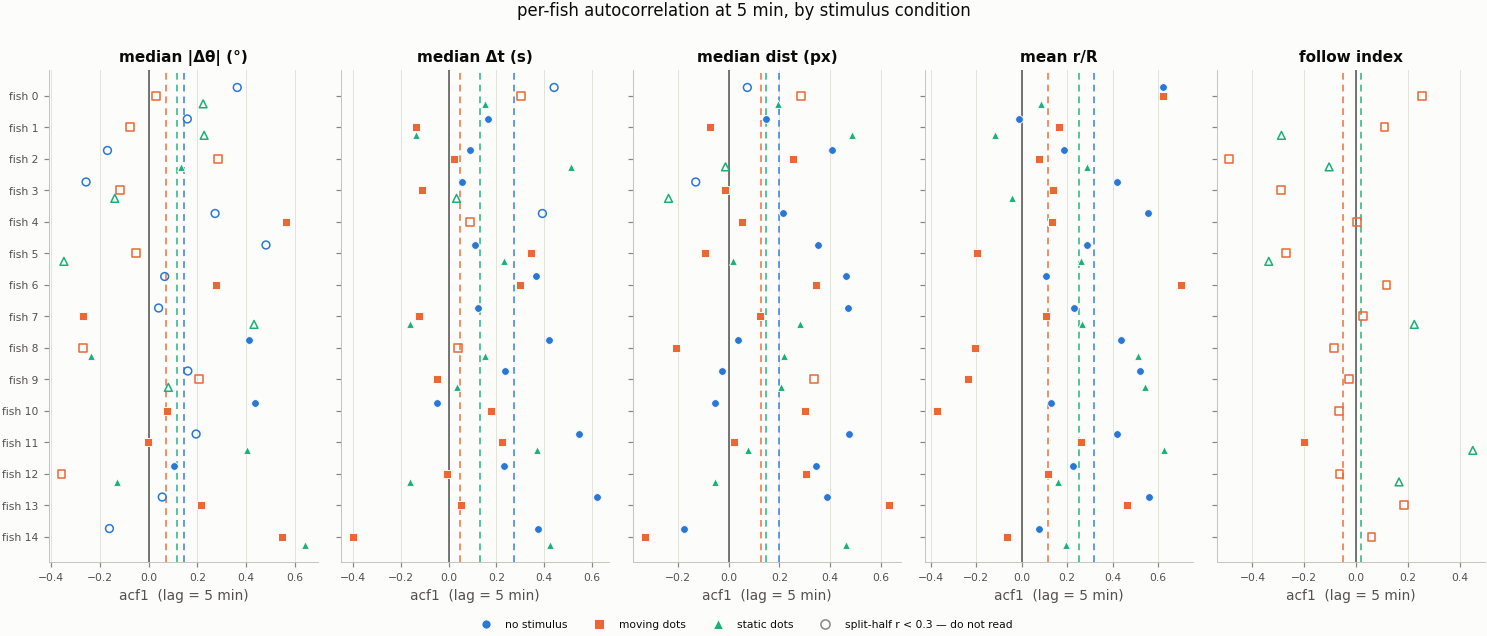

In [27]:
DE.show(DE.plot_acf_by_fish(df))

<a id="how-far-back-does-a-bout-remember"></a>
## How far back does a bout remember?

The lag-1 correlation of displacement, interval and |turn| within a run is positive in 15/15 fish, the signed turn's
is not consistent. Is the memory one bout deep (the correlation collapses between lag 1 and 2), or a slow decay (lags
2 and 3 stay positive: a slower process underneath, for which a few lags are a crude stand-in)? Pairs are formed within
a run only, so no correlation reaches across a pause. Within a fish the interval resamples its runs (the pairs of a run
are not independent); across fish, the median's interval resamples the fish.

[↑ back to contents](#contents)

15 fish x 4 channels x 5 lags, 979 runs, 2000 run-resamples each


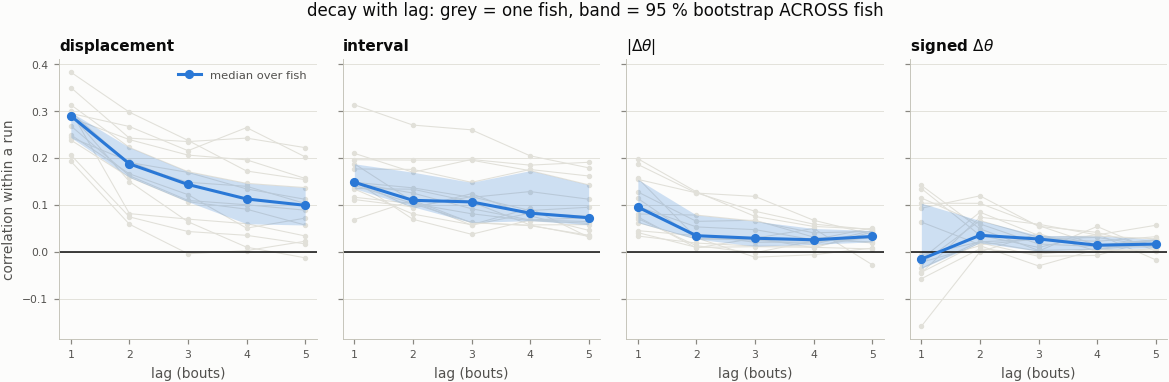

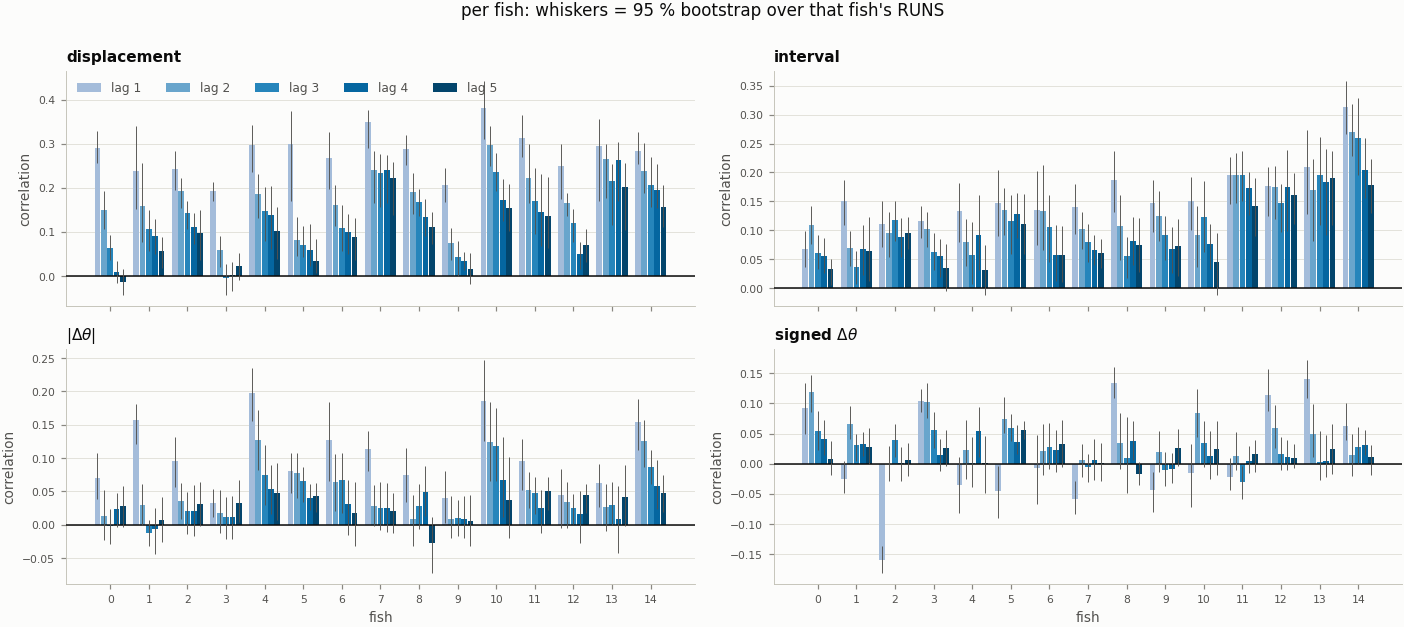

,channel,lag,median,med_lo,med_hi,same_sign,fish_CI_excl_0
0,displacement,1,0.289,0.243,0.297,15/15,15/15
1,displacement,2,0.187,0.158,0.222,15/15,15/15
2,displacement,3,0.143,0.106,0.170,14/15,14/15
3,displacement,4,0.112,0.060,0.145,15/15,13/15
4,displacement,5,0.099,0.057,0.136,14/15,12/15
5,interval,1,0.148,0.134,0.187,15/15,15/15
6,interval,2,0.109,0.095,0.169,15/15,15/15
7,interval,3,0.106,0.062,0.148,15/15,15/15
8,interval,4,0.082,0.066,0.172,15/15,15/15
9,interval,5,0.072,0.057,0.142,15/15,12/15


In [28]:
DE.lag_memory(df)

**Reading it.** Displacement and interval decay gradually and stay positive at lags 2-5 in nearly every fish: the
lags sample a slower process, and a model given lag-1 inputs alone can reproduce the lag-1 number and still miss what
produces it. The signed turn is the control: no consistent sign at lag 1, and none expected further back.

<a id="the-long-timescale-the-fish-or-the-schedule"></a>
## The long timescale: the fish or the schedule?

**A. The statistic the models are scored on.** `twin.generative_metrics.win_acf1` on the real fish: log interval, log
displacement or r/R; windows of 60 bouts inside one run; window means demeaned within the fish (so a fixed difference
between fish cannot contribute); lag-1 correlation between adjacent windows of the same run.

[↑ back to contents](#contents)

In [29]:
DE.window_acf_real(df).round(3)

median over fish: {'interval': 0.359, 'displacement': 0.276, 'radial position': 0.417}; positive in {'interval': '11/12', 'displacement': '10/12', 'radial position': '11/12'}
median interval 1.23 s, so a 60-bout window is about 74 s


,active_bouts,interval,displacement,radial position
fish,,,,
0,4530,0.241,-0.110,0.510
1,5257,0.484,0.189,0.176
2,5522,0.320,0.336,0.118
3,4714,0.060,0.005,0.547
4,3034,NaN,NaN,NaN
5,6787,0.627,0.207,0.575
6,2934,NaN,NaN,NaN
7,6409,0.276,0.675,0.596
8,3069,0.398,-0.223,-0.033


**B. Is it reachable with lags?** The window correlation against the window size, against a block shuffle (blocks of
10 bouts: keeps every dependence shorter than 10 bouts, what a ten-lag model could at best reproduce) and a full
shuffle (must be 0, else the estimator is biased). Both shuffles pool a fish's runs and re-split them into runs of the
same lengths. Large windows use only long runs, a selected (more active) subset: the coverage is printed.

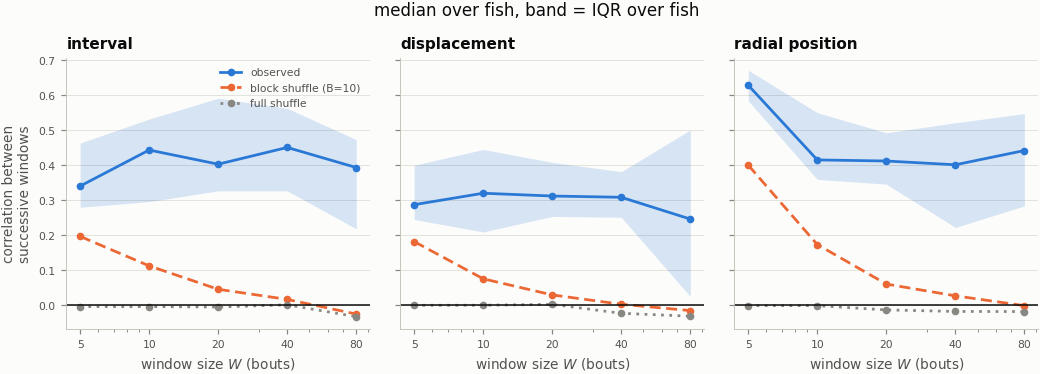

observed minus block-shuffled (median over fish): what ten lags cannot reach


,interval,displacement,radial position
W=5,0.153,0.106,0.214
W=10,0.332,0.234,0.236
W=20,0.374,0.288,0.358
W=40,0.465,0.313,0.385
W=80,0.413,0.272,0.413


bouts contributing (of 69567 active)


,interval,displacement,radial position
W=5,68280,68280,68280
W=10,66315,66315,66315
W=20,61969,61969,61969
W=40,54532,54532,54532
W=80,43396,43396,43396


In [30]:
DE.window_acf_vs_shuffles(df)

**C. The fish or the programme?** The programme is identical and synchronous for all 15 fish, so whatever it drives is
shared. In bins of one 110 s stimulus cycle, each fish's own lag-1 correlation across cycles against its correlation
with the mean of the other 14: a large own correlation with a small shared one means each fish drifts on its own (a
latent state is the right representation); a shared one would point to the stimulus. A small shared component does not
prove there is none, only that it is small next to the individual one at this timescale.

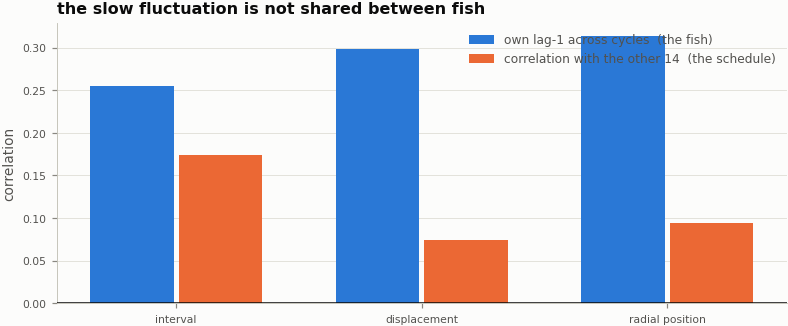

,channel,own_lag1,cross_fish,own_pos,cross_pos,n_cycles
0,interval,0.256,0.174,14/15,15/15,90
1,displacement,0.299,0.075,15/15,10/15,90
2,radial position,0.314,0.094,15/15,12/15,90


In [31]:
DE.fish_or_schedule(df).round(3)